# Step 8N (gimbal phase 2): Measurement noise

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have** | a clean logged angle trajectory from the hand simulator (the PD balance run of step 7, with damping and friction on) |
| **Unknown** | none, we create the data a real sensor would give |
| **Set to 0** | nothing in the dynamics. The simulation stays noise-free, noise is added to the **logged** angles afterwards |
| **NEW in this step** | the noise model: Gaussian, optional quantization |
| **What we get** | noisy angle data with known $\sigma$, saved for Chapter 2 |
| **Check** | not against MuJoCo. The noise itself must have mean 0 and std $\sigma$ within sampling error |

## 2. The equations

**8N.1 Gaussian measurement noise**

$$\tilde q_{k,i}=q_{k,i}+\eta_{k,i},\qquad \eta_{k,i}\sim\mathcal N(0,\sigma^2)\ \text{independent for each sample and each angle}$$

$\sigma=0.01$ rad (the value used in the earlier notebook). A fixed random seed makes the run repeatable.

**8N.2 What to check.** With $N$ samples of $\eta$, the sample mean and sample std scatter around $0$ and $\sigma$ by

$$\text{std error of the mean}=\frac{\sigma}{\sqrt N},\qquad \text{std error of the sample std}\approx\frac{\sigma}{\sqrt{2N}}$$

We pass if both are within 4 standard errors.

**8N.3 Encoder quantization (optional second noise).** A 12-bit encoder reads angles in steps of

$$\Delta_{\text{enc}}=\frac{2\pi}{4096}=1.534\times10^{-3}\ \text{rad},\qquad \tilde q=\Delta_{\text{enc}}\operatorname{round}\!\left(\frac{q}{\Delta_{\text{enc}}}\right)$$

The error is spread evenly over $\pm\Delta_{\text{enc}}/2$, with std $\Delta_{\text{enc}}/\sqrt{12}=4.4\times10^{-4}$ rad. Much smaller than $\sigma$.

**8N.4 Why we do not difference noisy angles to get velocity**

$$\hat{\dot q}_k=\frac{\tilde q_{k+1}-\tilde q_k}{\Delta t}\ \Rightarrow\ \text{std}=\frac{\sqrt2\,\sigma}{\Delta t}=14.1\ \text{rad/s}$$

The real rates are about 1 rad/s, so the noise is 14 times larger than the signal.

**8N.5 Link to Chapter 2.** The covariance of fitted parameters is approximately

$$\Sigma\approx\sigma^{2}\left(J^{\mathsf T}J\right)^{-1}$$

and $\sigma$ here is exactly the $\sigma$ of 8N.1.

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $\sigma$ | noise std | rad | **NEW**, known input (0.01) | `noise_std` |
| $\eta$ | noise samples | rad | **NEW**, output | `noise_samples` |
| $\tilde q$ | noisy measurement | rad | **NEW**, output | `noisy_angles` |
| $\Delta_{\text{enc}}$ | encoder step | rad | **NEW**, known input | `encoder_step` |
| $N$ | number of samples | 1 | output | `n_samples` |

## 3. Plug in, get out

```
clean angles q (from the PD run) + sigma + seed
   -> 8N.1 draw eta, add -> noisy angles
   -> 8N.2 check mean and std of (noisy - clean)
   -> 8N.3 quantized version, 8N.4 differenced velocity noise
   -> save clean and noisy arrays for Chapter 2
```

## 4. Conclusion

You hold data that looks like a measurement: clean physics plus known-size noise. The overlay in step 4 still compares clean with clean. The noisy arrays go to Chapter 2.


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore


NOTEBOOK_NAME = "8N_measurement_noise"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/8N_measurement_noise


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y

VISCOUS_DAMPING_VALUE = 0.04  # N*m*s/rad, foundational (used where a run turns damping on)
COULOMB_FRICTION_VALUE = 0.02  # N*m, foundational (used where a run turns friction on)
friction_smoothing_width = 1e-3  # rad/s, foundational (tanh width, equation 3.2)

motor_gear = 1.0  # 1, foundational (gear 1: the command IS the torque)
motor_torque_limit = 3.0  # N*m, foundational (command limit of each motor)


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def viscous_torque(rates, viscous_damping):
    return -viscous_damping * rates  # N*m, equation 2.1


def coulomb_torque(rates, coulomb_friction):
    return -coulomb_friction * np.tanh(rates / friction_smoothing_width)  # N*m, equation 3.2


def angular_acceleration(angles, rates, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    total_torque = motor_torque
    total_torque = total_torque + viscous_torque(rates, viscous_damping)
    total_torque = total_torque + coulomb_torque(rates, coulomb_friction)
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque, viscous_damping, coulomb_friction)])


def rk4_step(state, motor_torque, time_step, viscous_damping=0.0, coulomb_friction=0.0):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque, viscous_damping, coulomb_friction)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque, viscous_damping, coulomb_friction)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque, viscous_damping, coulomb_friction)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque, viscous_damping, coulomb_friction)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: motor torque and the run (equations 5.1 to 5.4)
# What we have: a command function that returns the motor command from (angles, rates, step_index)
# What we want: angle, rate, energy and torque logs (row k is the state at t = (k + 1) * time_step)
# Why: the command is clipped to the motor limit and multiplied by the gear, then held constant over the step
# Formulas:
#   motor_torque = motor_gear * clip(motor_command, -motor_torque_limit, +motor_torque_limit)
# ─────────────────────────────────────────────


def motor_torque_from_command(motor_command):
    return motor_gear * np.clip(motor_command, -motor_torque_limit, motor_torque_limit)  # N*m


def simulate(start_angles, start_rates, n_steps, viscous_damping=0.0, coulomb_friction=0.0, command_function=None, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    angle_log, rate_log, energy_log, torque_log = [], [], [], []
    for step_index in range(n_steps):
        if command_function is None:
            motor_command = np.zeros(2)
        else:
            motor_command = command_function(state[:2], state[2:], step_index)  # uses the state at the START of the step
        motor_torque = motor_torque_from_command(motor_command)
        state = rk4_step(state, motor_torque, time_step, viscous_damping, coulomb_friction)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        torque_log.append(motor_torque.copy())
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log),
            "motor_torque": np.array(torque_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 7: PD law (equation 7.1)
# What we have: the state at the start of each step, the gains, the target (upright, still)
# What we want: motor_command for each step
# Why: feedback turns the unstable equilibrium into a stable one
# Formulas:
#   motor_command = -kp (angles - target_angles) - kd (rates - target_rates)
# ─────────────────────────────────────────────

proportional_gain = 9.81  # N*m/rad, foundational
derivative_gain = 2.52  # N*m*s/rad, foundational
target_angles = np.zeros(2)  # rad, upright
target_rates = np.zeros(2)  # rad/s, still


def pd_command(angles, rates, step_index):
    return -proportional_gain * (angles - target_angles) - derivative_gain * (rates - target_rates)


outer_angle: mean = +2.93e-04 (limit 5.7e-04), std = 0.00984 (sigma 0.01, limit +-4.0e-04)
inner_angle: mean = +8.24e-06 (limit 5.7e-04), std = 0.00996 (sigma 0.01, limit +-4.0e-04)
encoder step = 1.534e-03 rad, quantization error std = 4.69e-04 rad (theory 4.43e-04)
velocity noise by differencing: std = 14.0 rad/s (theory sqrt(2) sigma / dt = 14.1), true rates reach 0.08 rad/s


saved the figure


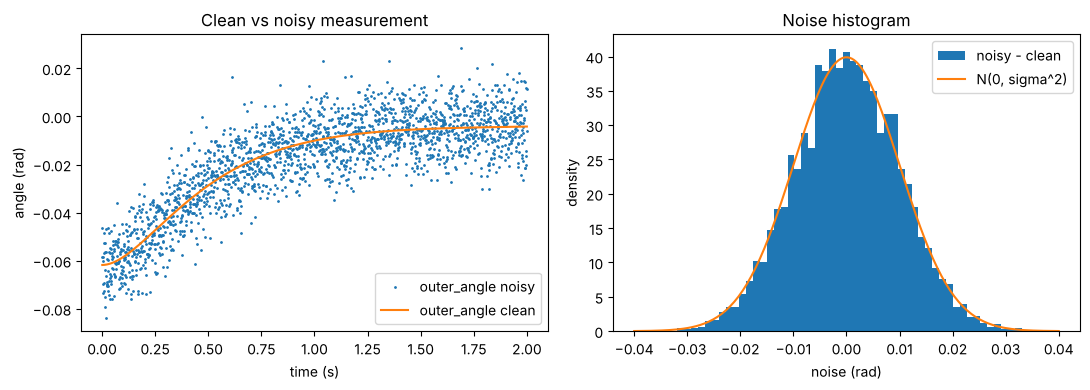

saved the data


In [8]:
# ─────────────────────────────────────────────
# STEP 8: measurement noise added after the clean simulation (equations 8N.1 to 8N.4)
# What we have: a clean PD balance run (damping and friction on) and the noise std sigma = 0.01 rad
# What we want: noisy angles, a quantized version, and the noise statistics
# Why: a real sensor gives clean physics plus noise; Chapter 2 needs noisy data with known sigma
# ─────────────────────────────────────────────

noise_std = 0.01  # rad, foundational (angle sensor quality)
RANDOM_SEED = 57  # fixed so the run repeats
N_STEPS = 5000

clean_result = simulate(start_angles, start_rates, N_STEPS, VISCOUS_DAMPING_VALUE, COULOMB_FRICTION_VALUE, pd_command)
clean_angles = clean_result["angles"]  # rad, shape (rows, 2)
n_rows = len(clean_angles)

random_generator = np.random.default_rng(RANDOM_SEED)
noise_samples = random_generator.normal(0.0, noise_std, size=clean_angles.shape)  # equation 8N.1
noisy_angles = clean_angles + noise_samples

# equation 8N.2: mean and std of the added noise, within 4 standard errors
residual = noisy_angles - clean_angles
for angle_name, column in (("outer_angle", 0), ("inner_angle", 1)):
    sample_mean = residual[:, column].mean()
    sample_std = residual[:, column].std()
    mean_limit = 4 * noise_std / np.sqrt(n_rows)
    std_limit = 4 * noise_std / np.sqrt(2 * n_rows)
    print(f"{angle_name}: mean = {sample_mean:+.2e} (limit {mean_limit:.1e}), std = {sample_std:.5f} (sigma {noise_std}, limit +-{std_limit:.1e})")
    assert abs(sample_mean) < mean_limit and abs(sample_std - noise_std) < std_limit

# equation 8N.3: 12-bit encoder quantization
encoder_step = 2 * np.pi / 4096  # rad
quantized_angles = encoder_step * np.round(clean_angles / encoder_step)
quantization_std = (quantized_angles - clean_angles).std()
print(f"encoder step = {encoder_step:.3e} rad, quantization error std = {quantization_std:.2e} rad (theory {encoder_step / np.sqrt(12):.2e})")
assert abs(quantization_std - encoder_step / np.sqrt(12)) / (encoder_step / np.sqrt(12)) < 0.1

# equation 8N.4: velocity by differencing noisy angles
differenced_rates = np.diff(noisy_angles, axis=0) / time_step  # rad/s
true_rates = clean_result["rates"][:-1]
rate_noise_std = (differenced_rates - true_rates).std()
print(f"velocity noise by differencing: std = {rate_noise_std:.1f} rad/s (theory sqrt(2) sigma / dt = {np.sqrt(2) * noise_std / time_step:.1f}), true rates reach {np.abs(true_rates).max():.2f} rad/s")

time_axis = (np.arange(n_rows) + 1) * time_step
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(time_axis[:2000], noisy_angles[:2000, 0], ".", markersize=2, label="outer_angle noisy")
axes[0].plot(time_axis[:2000], clean_angles[:2000, 0], label="outer_angle clean")
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("angle (rad)")
axes[0].set_title("Clean vs noisy measurement")
axes[0].legend()
axes[1].hist(residual.ravel(), bins=60, density=True, label="noisy - clean")
grid = np.linspace(-4 * noise_std, 4 * noise_std, 200)
axes[1].plot(grid, np.exp(-0.5 * (grid / noise_std) ** 2) / (noise_std * np.sqrt(2 * np.pi)), label="N(0, sigma^2)")
axes[1].set_xlabel("noise (rad)")
axes[1].set_ylabel("density")
axes[1].set_title("Noise histogram")
axes[1].legend()
figure.tight_layout()
figure.savefig(os.path.join(RESULT_DIR, f"measurement_noise_{TIMESTAMP}.png"), dpi=150)
print("saved the figure")
plt.show()

np.savez(os.path.join(RESULT_DIR, f"noisy_data_{TIMESTAMP}.npz"), time=time_axis, clean_angles=clean_angles, noisy_angles=noisy_angles,
         quantized_angles=quantized_angles, noise_std=noise_std, seed=RANDOM_SEED)
print("saved the data")
